
# 통신 서비스 고객 이탈 예측 및 주요 요인 분석

## 1. 프로젝트 개요

### 1.1 프로젝트 목적

본 프로젝트는 통신 서비스 고객 데이터를 활용하여 고객 이탈 여부를 예측하고, 고객 이탈에 영향을 미치는 주요 요인을 분석하는 것을 목적으로 한다.

이를 위해 데이터 탐색 및 시각화를 통해 고객의 특성을 파악하고, 다양한 머신러닝 분류 모델을 적용하여 예측 성능을 비교하고자 한다.

### 1.2 분석 목표

- 통신 서비스 고객 데이터의 특성 및 분포 파악
- 고객 이탈 여부와 관련된 주요 요인 분석
- 머신러닝 모델을 활용한 고객 이탈 예측
- 모델별 예측 성능 비교 및 최적의 모델 선정

### 1.3 사용 데이터

- 데이터명: Telco Customer Churn
- 데이터 출처: IBM Telco Customer Churn Dataset
- 데이터 유형: 통신 서비스 고객 정보
- 분석 대상: 고객의 서비스 이용 정보 및 이탈 여부


In [1]:

# 데이터 분석에 필요한 라이브러리 불러오기

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 데이터 시각화 기본 설정
plt.rcParams['figure.figsize'] = (10, 6)
sns.set_theme(style='whitegrid')



In [2]:

from google.colab import files

uploaded = files.upload()


Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn (1).csv



## 2.1 데이터 불러오기


In [3]:

# CSV 파일 불러오기
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')



## 2.2 데이터 기본 정보 확인


In [4]:

# 데이터의 행과 열 확인
print("데이터 크기:", df.shape)

# 데이터 상위 5개 행 확인
display(df.head())

# 데이터의 기본 정보 확인
df.info()


데이터 크기: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 



## 2.3 기초 통계량 확인


In [5]:

# 수치형 데이터의 기초 통계량 확인
display(df.describe())

# 중복 데이터 확인
print("중복 데이터 수:", df.duplicated().sum())


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


중복 데이터 수: 0


In [6]:

# 데이터 상위 5개 행 다시 확인
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



### 데이터 탐색 결과

데이터의 상위 5개 행을 확인한 결과, 각 행은 개별 고객을 나타내며 각 열은 고객의 기본 정보, 서비스 이용 현황 및 요금 정보를 포함하고 있다.

주요 변수로는 고객의 가입 기간(tenure), 월별 요금(MonthlyCharges), 계약 유형(Contract), 결제 방법(PaymentMethod) 및 고객 이탈 여부(Churn) 등이 있다.

이러한 변수들을 활용하여 고객 이탈과 관련된 패턴 및 주요 요인을 분석하고자 한다.


In [7]:

print("중복 데이터 수:", df.duplicated().sum())


중복 데이터 수: 0



### 데이터 탐색 결과 요약

- 전체 데이터는 7,043개의 행과 21개의 열로 구성되어 있다.
- 고객 정보, 서비스 이용 정보 및 요금 관련 변수가 포함되어 있다.
- 데이터 확인 결과, 중복된 행은 발견되지 않았다.
- TotalCharges 변수에는 공백 형태의 데이터가 존재하므로 추후 전처리가 필요하다.



# 3. 데이터 시각화

데이터 시각화를 통해 고객 이탈 현황과 주요 변수 간의 관계를 파악하고, 고객 이탈과 관련된 패턴을 분석하고자 한다.


In [8]:

# 그래프 폰트 설정
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False


Churn
No     5174
Yes    1869
Name: count, dtype: int64


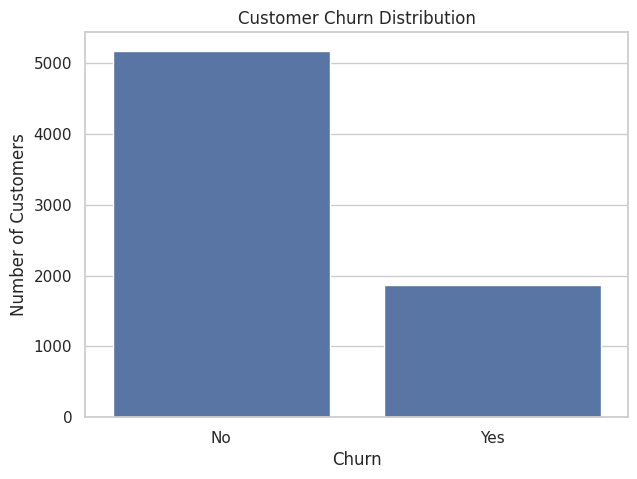

In [9]:

# 고객 이탈 여부별 인원수 확인
churn_counts = df['Churn'].value_counts()

print(churn_counts)

# 고객 이탈 여부 시각화
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='Churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')

plt.show()



### 분석 결과

전체 고객 중 서비스를 유지한 고객은 5,174명이며,
서비스를 이탈한 고객은 1,869명으로 나타났다.

전체 고객 중 약 26.5%가 서비스를 이탈한 것으로 확인되었다.

이를 통해 고객 이탈 여부에 따른 데이터 분포에 차이가
존재한다는 것을 확인할 수 있다.



### 3.2 계약 유형별 고객 이탈률 분석

고객의 계약 유형에 따라 이탈률에 차이가 있는지 분석하고자 한다.

계약 유형별 고객 이탈률을 비교하여 계약 기간과 고객 이탈 간의 관계를 확인한다.


Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn, dtype: float64


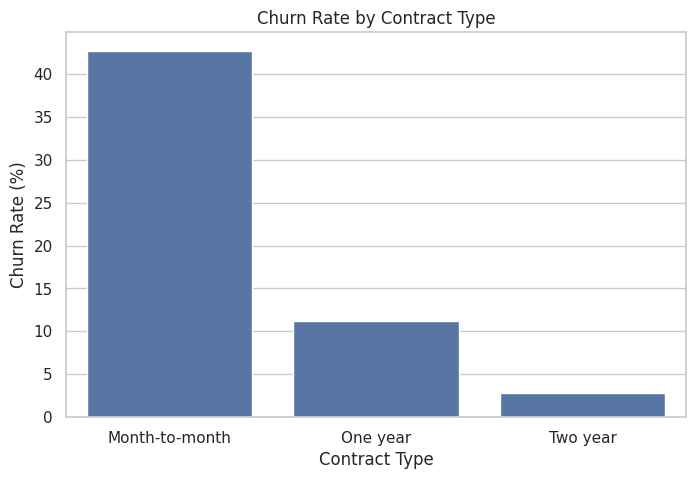

In [10]:

# 계약 유형별 고객 이탈률 계산
contract_churn = df.groupby('Contract')['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
)

print(contract_churn)

# 계약 유형별 고객 이탈률 시각화
plt.figure(figsize=(8, 5))

sns.barplot(
    x=contract_churn.index,
    y=contract_churn.values
)

plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')

plt.show()



### 분석 결과

계약 유형별 고객 이탈률을 분석한 결과, 월 단위 계약(Month-to-month)을 이용하는 고객의 이탈률이 약 42.71%로 가장 높게 나타났다.

1년 계약(One year)의 이탈률은 약 11.27%였으며, 2년 계약(Two year)의 이탈률은 약 2.83%로 가장 낮았다.

이를 통해 계약 기간이 짧은 고객일수록 이탈률이 높게 나타나는 경향을 확인할 수 있었다.

따라서 계약 유형은 고객 이탈과 관련된 주요 요인 중 하나일 가능성이 있다.



### 3.3 가입 기간별 고객 이탈률 분석

고객의 가입 기간(tenure)에 따라 이탈률에 차이가 있는지 분석하고자 한다.

가입 기간을 구간별로 나누어 각 구간의 고객 이탈률을 비교하고, 가입 기간과 고객 이탈 간의 관계를 파악한다.


TenureGroup
0-12 months     47.438243
13-24 months    28.710938
25-48 months    20.388959
49-72 months     9.513176
Name: Churn, dtype: float64


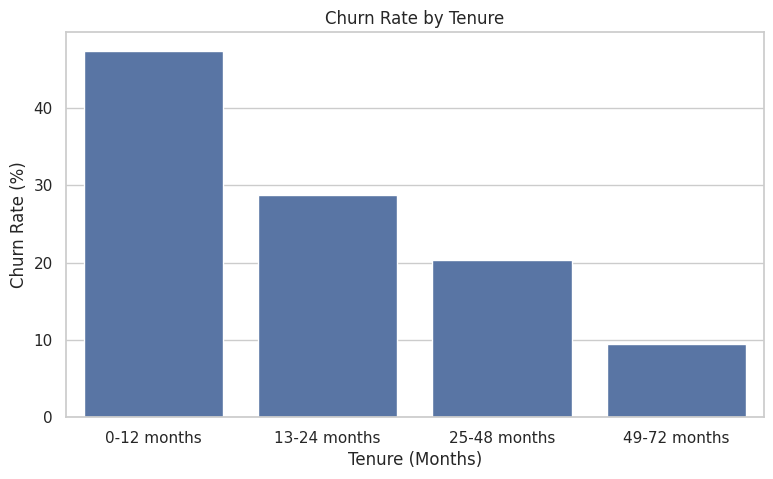

In [11]:

# 고객 가입 기간을 구간별로 분류
df['TenureGroup'] = pd.cut(
    df['tenure'],
    bins=[-1, 12, 24, 48, 72],
    labels=['0-12 months', '13-24 months',
            '25-48 months', '49-72 months']
)

# 가입 기간별 고객 이탈률 계산
tenure_churn = df.groupby(
    'TenureGroup', observed=False
)['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
)

print(tenure_churn)

# 가입 기간별 고객 이탈률 시각화
plt.figure(figsize=(9, 5))

sns.barplot(
    x=tenure_churn.index,
    y=tenure_churn.values
)

plt.title('Churn Rate by Tenure')
plt.xlabel('Tenure (Months)')
plt.ylabel('Churn Rate (%)')

plt.show()



### 분석 결과

가입 기간별 고객 이탈률을 분석한 결과, 가입 기간이 0~12개월인 고객의 이탈률이 약 47.44%로 가장 높게 나타났다.

반면 가입 기간이 49~72개월인 고객의 이탈률은 약 9.51%로 가장 낮았다.

이를 통해 가입 기간이 짧은 고객일수록 이탈률이 높고, 가입 기간이 길어질수록 이탈률이 낮아지는 경향을 확인할 수 있었다.

따라서 고객의 가입 기간은 고객 이탈과 관련된 중요한 분석 변수라고 판단된다.



### 3.4 결제 방법별 고객 이탈률 분석

고객의 결제 방법에 따라 이탈률에 차이가 있는지 분석하고자 한다.

결제 방법별 고객 이탈률을 비교하여 결제 방식과 고객 이탈 간의 관계를 파악한다.


PaymentMethod
Electronic check             45.285412
Mailed check                 19.106700
Bank transfer (automatic)    16.709845
Credit card (automatic)      15.243101
Name: Churn, dtype: float64


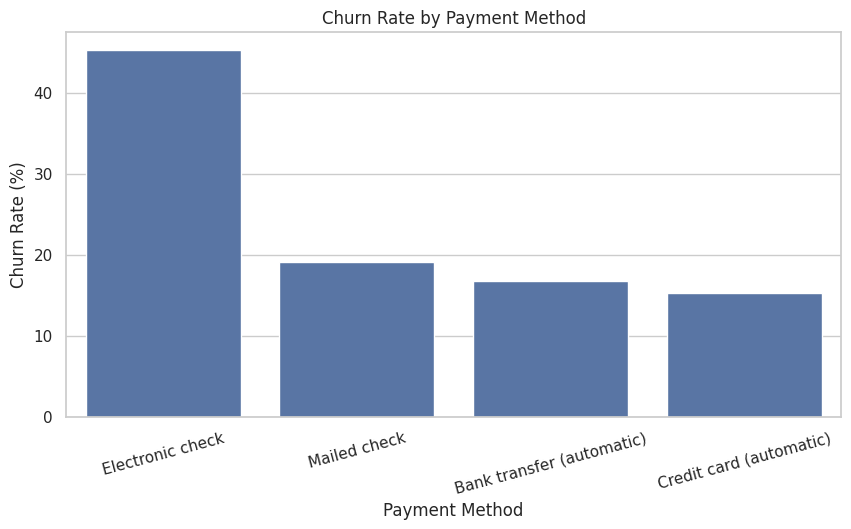

In [12]:

# 결제 방법별 고객 이탈률 계산
payment_churn = df.groupby('PaymentMethod')['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
)

# 이탈률 내림차순 정렬
payment_churn = payment_churn.sort_values(ascending=False)

print(payment_churn)

# 결제 방법별 고객 이탈률 시각화
plt.figure(figsize=(10, 5))

sns.barplot(
    x=payment_churn.index,
    y=payment_churn.values
)

plt.title('Churn Rate by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=15)

plt.show()



### 분석 결과

결제 방법별 고객 이탈률을 분석한 결과, 전자 수표(Electronic check)를 사용하는 고객의 이탈률이 약 45.29%로 가장 높게 나타났다.

우편 수표(Mailed check)의 이탈률은 약 19.11%였으며, 자동 은행 이체(Bank transfer)의 이탈률은 약 16.71%로 나타났다.

자동 신용카드 결제(Credit card)의 이탈률은 약 15.24%로 가장 낮았다.

이를 통해 전자 수표를 사용하는 고객의 이탈률이 다른 결제 방법을 사용하는 고객보다 높게 나타나는 경향을 확인할 수 있었다.

따라서 결제 방법은 고객 이탈과 관련된 주요 요인 중 하나일 가능성이 있다.



### 3.5 월별 요금과 고객 이탈의 관계 분석

고객의 월별 요금(MonthlyCharges)에 따라 이탈 여부에 차이가 있는지 분석하고자 한다.

이탈한 고객과 서비스를 유지한 고객의 월별 요금 분포를 비교하여 요금 수준과 고객 이탈 간의 관계를 파악한다.


,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,61.265124,31.092648,18.25,25.10,64.425,88.4,118.75
Yes,1869.0,74.441332,24.666053,18.85,56.15,79.650,94.2,118.35


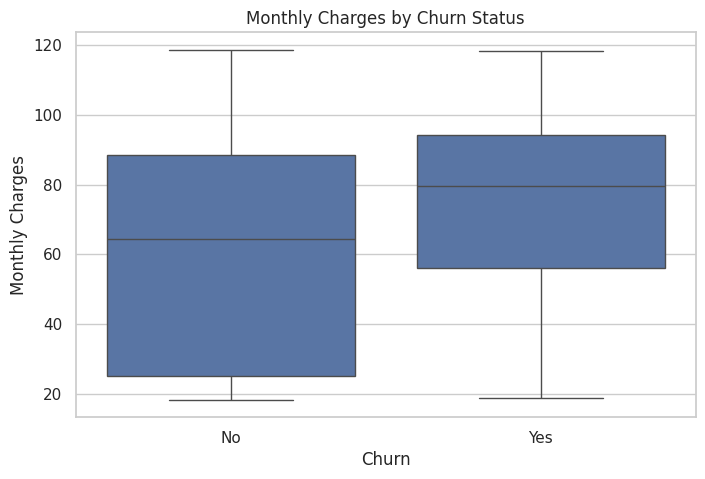

In [13]:

# 이탈 여부에 따른 월별 요금의 기초 통계량 확인
monthly_charges = df.groupby('Churn')['MonthlyCharges'].describe()

display(monthly_charges)

# 고객 이탈 여부에 따른 월별 요금 분포 시각화
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Churn',
    y='MonthlyCharges'
)

plt.title('Monthly Charges by Churn Status')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')

plt.show()



### 분석 결과

고객 이탈 여부에 따른 월별 요금 분포를 분석한 결과, 이탈한 고객(Yes)의 평균 월별 요금은 약 74.44로 나타났다.

반면 서비스를 유지한 고객(No)의 평균 월별 요금은 약 61.27로, 이탈한 고객보다 낮게 나타났다.

중앙값을 비교한 결과에서도 이탈한 고객은 약 79.65, 서비스를 유지한 고객은 약 64.43으로 차이가 나타났다.

이를 통해 월별 요금이 높은 고객일수록 이탈률이 높게 나타나는 경향을 확인할 수 있었다.

따라서 월별 요금은 고객 이탈과 관련된 요인 중 하나일 가능성이 있으며, 요금 수준과 고객 이탈 간의 관계를 추가적으로 분석할 필요가 있다.



### 3.6 인터넷 서비스 유형별 고객 이탈률 분석

고객이 이용하는 인터넷 서비스 유형(InternetService)에 따라 이탈률에 차이가 있는지 분석하고자 한다.

인터넷 서비스 유형별 고객 이탈률을 비교하여 서비스 유형과 고객 이탈 간의 관계를 파악한다.


InternetService
Fiber optic    41.892765
DSL            18.959108
No              7.404980
Name: Churn, dtype: float64


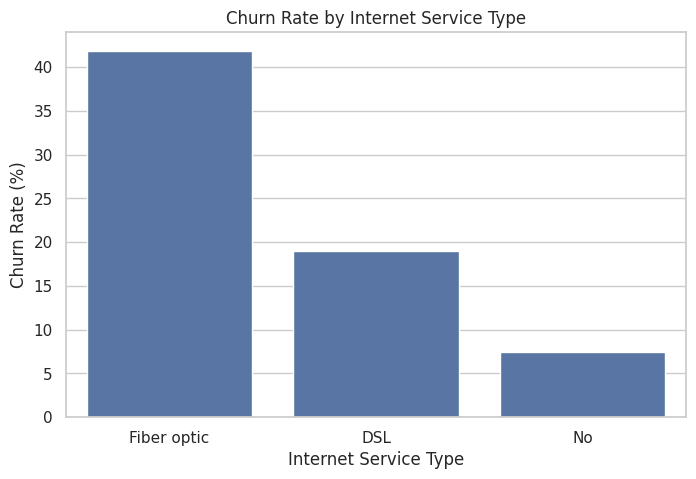

In [14]:

# 인터넷 서비스 유형별 고객 이탈률 계산
internet_churn = df.groupby('InternetService')['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
)

# 이탈률 내림차순 정렬
internet_churn = internet_churn.sort_values(ascending=False)

print(internet_churn)

# 인터넷 서비스 유형별 고객 이탈률 시각화
plt.figure(figsize=(8, 5))

sns.barplot(
    x=internet_churn.index,
    y=internet_churn.values
)

plt.title('Churn Rate by Internet Service Type')
plt.xlabel('Internet Service Type')
plt.ylabel('Churn Rate (%)')

plt.show()



### 분석 결과

인터넷 서비스 유형별 고객 이탈률을 분석한 결과, 광섬유 인터넷(Fiber optic)을 이용하는 고객의 이탈률이 약 41.89%로 가장 높게 나타났다.

DSL 인터넷을 이용하는 고객의 이탈률은 약 18.96%였으며, 인터넷 서비스를 이용하지 않는 고객(No)의 이탈률은 약 7.40%로 가장 낮았다.

이를 통해 광섬유 인터넷을 이용하는 고객의 이탈률이 다른 유형의 고객보다 높게 나타나는 경향을 확인할 수 있었다.

따라서 인터넷 서비스 유형은 고객 이탈과 관련된 주요 요인 중 하나일 가능성이 있다.



# 4. 데이터 전처리

머신러닝 모델 학습을 위해 데이터의 결측치와 불필요한 변수를 확인하고, 범주형 데이터를 모델이 학습할 수 있는 형태로 변환하고자 한다.

### 4.1 결측치 확인 및 처리

TotalCharges 변수에 공백 형태의 데이터가 존재하므로, 이를 결측치로 변환하고 데이터 유형을 숫자형으로 변경한다.


In [15]:

# TotalCharges 변수의 공백 제거 및 숫자형 변환
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'].str.strip(),
    errors='coerce'
)

# 결측치 개수 확인
print("결측치 개수:")
print(df.isnull().sum())

# 전체 결측치 개수 확인
print("\n전체 결측치 개수:", df.isnull().sum().sum())


결측치 개수:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
TenureGroup          0
dtype: int64

전체 결측치 개수: 11


In [16]:

# TotalCharges 결측치가 있는 행 제거
df = df.dropna(subset=['TotalCharges'])

# 결측치 제거 후 데이터 크기 확인
print("결측치 제거 후 데이터 크기:", df.shape)

# 남아 있는 결측치 확인
print("\n전체 결측치 개수:", df.isnull().sum().sum())


결측치 제거 후 데이터 크기: (7032, 22)

전체 결측치 개수: 0



### 결측치 처리 결과

TotalCharges 변수에서 총 11개의 결측치가 확인되었다.

이는 전체 데이터 7,043개 중 약 0.16%에 해당하는 적은 비율이므로, 해당 결측치가 포함된 행을 제거하였다.

결측치 제거 후 데이터는 7,032개의 행과 22개의 열로 구성되며, 남아 있는 결측치는 없는 것을 확인하였다.



### 4.2 불필요한 변수 제거

머신러닝 모델 학습에 불필요한 변수를 제거하고자 한다.

customerID는 고객을 구분하기 위한 식별자이므로 예측 변수로 활용하지 않는다.

또한 TenureGroup은 시각화 과정에서 생성한 변수이며, 기존 tenure 변수와 정보가 중복되므로 제거한다.


In [17]:

# 불필요한 변수 제거
df = df.drop(columns=['customerID', 'TenureGroup'])

# 변수 제거 후 데이터 크기 확인
print("변수 제거 후 데이터 크기:", df.shape)

# 남아 있는 변수 확인
print("\n남아 있는 변수 목록:")
print(df.columns.tolist())


변수 제거 후 데이터 크기: (7032, 20)

남아 있는 변수 목록:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']



### 4.3 독립 변수와 종속 변수 분리

머신러닝 모델 학습을 위해 독립 변수(X)와 종속 변수(y)를 분리한다.

독립 변수(X)는 고객의 기본 정보, 서비스 이용 정보 및 요금 정보를 포함하며, 종속 변수(y)는 고객 이탈 여부(Churn)로 설정한다.


In [18]:

# 독립 변수(X)와 종속 변수(y) 분리
X = df.drop(columns=['Churn'])
y = df['Churn']

# 데이터 크기 확인
print("독립 변수(X) 크기:", X.shape)
print("종속 변수(y) 크기:", y.shape)

# 종속 변수의 분포 확인
print("\n고객 이탈 여부 분포:")
print(y.value_counts())


독립 변수(X) 크기: (7032, 19)
종속 변수(y) 크기: (7032,)

고객 이탈 여부 분포:
Churn
No     5163
Yes    1869
Name: count, dtype: int64



### 4.4 범주형 변수 인코딩

머신러닝 모델은 문자열 형태의 범주형 데이터를 직접 처리할 수 없으므로, 원-핫 인코딩(One-Hot Encoding)을 적용하여 범주형 변수를 숫자형 데이터로 변환한다.

이를 통해 각 범주를 별도의 열로 표현하여 머신러닝 모델이 데이터를 학습할 수 있도록 한다.


In [19]:

# 범주형 변수와 수치형 변수 구분
categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

numerical_features = X.select_dtypes(
    exclude=['object']
).columns.tolist()

print("범주형 변수:")
print(categorical_features)

print("\n수치형 변수:")
print(numerical_features)

print("\n범주형 변수 개수:", len(categorical_features))
print("수치형 변수 개수:", len(numerical_features))


범주형 변수:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

수치형 변수:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

범주형 변수 개수: 15
수치형 변수 개수: 4



### 4.5 학습 데이터와 테스트 데이터 분리

머신러닝 모델의 학습 및 성능 평가를 위해 전체 데이터를 학습 데이터와 테스트 데이터로 분리한다.

전체 데이터의 80%는 모델 학습에 사용하고, 나머지 20%는 모델의 예측 성능을 평가하는 데 사용한다.

또한 stratify 옵션을 적용하여 학습 데이터와 테스트 데이터의 고객 이탈 여부 비율을 유지한다.


In [20]:

from sklearn.model_selection import train_test_split

# 학습 데이터와 테스트 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 데이터 크기 확인
print("학습 데이터 크기:", X_train.shape)
print("테스트 데이터 크기:", X_test.shape)

print("\n학습 데이터의 이탈 여부 비율:")
print(y_train.value_counts(normalize=True) * 100)

print("\n테스트 데이터의 이탈 여부 비율:")
print(y_test.value_counts(normalize=True) * 100)


학습 데이터 크기: (5625, 19)
테스트 데이터 크기: (1407, 19)

학습 데이터의 이탈 여부 비율:
Churn
No     73.422222
Yes    26.577778
Name: proportion, dtype: float64

테스트 데이터의 이탈 여부 비율:
Churn
No     73.418621
Yes    26.581379
Name: proportion, dtype: float64



### 4.6 데이터 전처리 파이프라인 구성

범주형 변수와 수치형 변수에 적합한 전처리 방법을 각각 적용하기 위해 ColumnTransformer를 사용한다.

범주형 변수에는 One-Hot Encoding을 적용하고, 수치형 변수에는 StandardScaler를 적용하여 데이터의 크기와 범위를 조정한다.

전처리 과정은 학습 데이터에 적합시키고 테스트 데이터에는 동일한 변환을 적용하여 데이터 누수를 방지한다.


In [21]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 범주형 변수와 수치형 변수 전처리 설정
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('num', StandardScaler(), numerical_features)
    ]
)

# 학습 데이터에 전처리 적용
X_train_processed = preprocessor.fit_transform(X_train)

# 테스트 데이터에 동일한 전처리 적용
X_test_processed = preprocessor.transform(X_test)

# 전처리 결과 확인
print("전처리된 학습 데이터 크기:", X_train_processed.shape)
print("전처리된 테스트 데이터 크기:", X_test_processed.shape)


전처리된 학습 데이터 크기: (5625, 45)
전처리된 테스트 데이터 크기: (1407, 45)



### 전처리 결과

범주형 변수에 One-Hot Encoding을 적용하고, 수치형 변수에 StandardScaler를 적용하여 데이터를 변환하였다.

전처리 결과, 기존 19개의 독립 변수는 45개의 수치형 특성으로 변환되었다.

최종적으로 학습 데이터는 5,625개의 행과 45개의 열로 구성되었으며, 테스트 데이터는 1,407개의 행과 45개의 열로 구성되었다.

이를 통해 머신러닝 모델 학습에 사용할 수 있는 데이터 전처리를 완료하였다.



# 5. 머신러닝 모델 학습

본 프로젝트에서는 고객 이탈 여부를 예측하기 위해 다양한 머신러닝 분류 모델을 학습하고 성능을 비교하고자 한다.

### 5.1 Logistic Regression (로지스틱 회귀)

Logistic Regression은 두 가지 범주 중 하나를 예측하는 이진 분류 알고리즘이다.

본 프로젝트에서는 고객의 기본 정보, 서비스 이용 정보 및 요금 정보를 학습하여 고객 이탈 여부를 예측하는 데 활용한다.


1.   List item
2.   List item



In [22]:

from sklearn.linear_model import LogisticRegression

# Logistic Regression 모델 생성
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# 모델 학습
lr_model.fit(X_train_processed, y_train)

print("Logistic Regression 모델 학습 완료!")


Logistic Regression 모델 학습 완료!


In [23]:

# 테스트 데이터를 사용하여 고객 이탈 여부 예측
lr_predictions = lr_model.predict(X_test_processed)

# 예측 결과 확인
print("예측 결과:")
print(lr_predictions[:20])

print("\n실제 결과:")
print(y_test.values[:20])


예측 결과:
['No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes' 'No' 'Yes' 'No' 'Yes' 'No'
 'No' 'Yes' 'Yes' 'Yes' 'No' 'No']

실제 결과:
['No' 'No' 'No' 'Yes' 'No' 'Yes' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No' 'No'
 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'No']



### 모델 학습 및 예측 결과

Logistic Regression 모델을 사용하여 학습 데이터를 기반으로 고객 이탈 여부를 학습하였다.

이후 테스트 데이터를 입력하여 고객 이탈 여부를 예측하였으며, 실제 고객 이탈 여부와 예측 결과를 비교할 수 있음을 확인하였다.

모델의 구체적인 예측 성능은 다음 단계에서 평가 지표를 활용하여 분석하고자 한다.



### 5.2 Decision Tree (의사결정나무)

Decision Tree는 여러 조건에 따라 데이터를 분류하는 머신러닝 알고리즘이다.

각 변수의 조건을 기준으로 데이터를 여러 그룹으로 나누며, 이를 통해 고객 이탈 여부를 예측한다.

의사결정 과정을 트리 구조로 표현할 수 있어 모델의 예측 과정을 이해하기 쉽다는 장점이 있다.


In [24]:

from sklearn.tree import DecisionTreeClassifier

# Decision Tree 모델 생성
dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

# 모델 학습
dt_model.fit(X_train_processed, y_train)

# 테스트 데이터를 사용하여 고객 이탈 여부 예측
dt_predictions = dt_model.predict(X_test_processed)

# 예측 결과 확인
print("\n예측 결과:")
print(dt_predictions[:20])



예측 결과:
['No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes' 'No' 'Yes' 'No' 'Yes' 'No'
 'No' 'Yes' 'Yes' 'Yes' 'No' 'No']



### 모델 학습 및 예측 결과

Decision Tree 모델을 사용하여 학습 데이터를 기반으로 고객 이탈 여부를 학습하였다.

학습된 모델에 테스트 데이터를 입력하여 고객 이탈 여부를 예측하였으며, 예측 결과가 정상적으로 출력되는 것을 확인하였다.

모델의 구체적인 예측 성능은 이후 평가 지표를 활용하여 분석하고자 한다.



### 5.3 Random Forest (랜덤 포레스트)

Random Forest는 여러 개의 Decision Tree를 생성하고, 각 트리의 예측 결과를 결합하여 최종 결과를 도출하는 앙상블 학습 알고리즘이다.

여러 개의 의사결정나무를 활용하여 예측의 안정성을 높이고 과적합을 줄이는 데 도움을 줄 수 있다.

본 프로젝트에서는 Random Forest를 활용하여 고객 이탈 여부를 예측하고자 한다.


In [25]:

from sklearn.ensemble import RandomForestClassifier

# Random Forest 모델 생성
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42
)

# 모델 학습
rf_model.fit(X_train_processed, y_train)

# 테스트 데이터를 사용하여 고객 이탈 여부 예측
rf_predictions = rf_model.predict(X_test_processed)

# 예측 결과 확인
print("\n예측 결과:")
print(rf_predictions[:20])



예측 결과:
['No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes' 'No' 'Yes' 'No' 'Yes' 'No'
 'No' 'Yes' 'Yes' 'Yes' 'No' 'No']



### 모델 학습 및 예측 결과

Random Forest 모델을 사용하여 여러 개의 Decision Tree를 학습하고, 이를 결합하여 고객 이탈 여부를 예측하였다.

테스트 데이터를 입력한 결과, 고객 이탈 여부에 대한 예측 결과가 정상적으로 출력되는 것을 확인하였다.

모델의 구체적인 예측 성능은 이후 평가 지표를 활용하여 분석하고자 한다.



### 5.4 XGBoost (익스트림 그래디언트 부스팅)

XGBoost는 여러 개의 의사결정나무를 순차적으로 학습하여 예측 성능을 개선하는 앙상블 학습 알고리즘이다.

이전 모델의 예측 오차를 보완하는 방향으로 새로운 트리를 학습하며, 이를 통해 높은 예측 성능을 얻을 수 있다.

본 프로젝트에서는 XGBoost를 활용하여 고객 이탈 여부를 예측하고자 한다.


In [26]:

!pip install xgboost


In [27]:

from xgboost import XGBClassifier

# XGBoost 모델 생성
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss'
)

# 모델 학습
xgb_model.fit(
    X_train_processed,
    (y_train == 'Yes').astype(int)
)


# 테스트 데이터를 사용하여 고객 이탈 여부 예측
xgb_predictions = xgb_model.predict(X_test_processed)

# 예측 결과를 원래 범주형 값으로 변환
xgb_predictions = np.where(
    xgb_predictions == 1,
    'Yes',
    'No'
)

# 예측 결과 확인
print("\n예측 결과:")
print(xgb_predictions[:20])



예측 결과:
['No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'Yes' 'No' 'Yes' 'No' 'Yes'
 'No' 'No' 'Yes' 'Yes' 'Yes' 'No' 'No']



### 모델 학습 및 예측 결과

XGBoost 모델을 사용하여 이전 모델의 예측 오차를 보완하는 방식으로 학습을 진행하였다.

학습된 모델에 테스트 데이터를 입력하여 고객 이탈 여부를 예측하였으며, 예측 결과가 정상적으로 출력되는 것을 확인하였다.

모델별 예측 결과에는 일부 차이가 나타났으며, 구체적인 성능 비교는 다음 단계에서 평가 지표를 활용하여 진행하고자 한다.



# 6. 모델 성능 평가 및 비교

학습한 네 가지 머신러닝 모델의 예측 성능을 비교하고 가장 적합한 모델을 선정하고자 한다.

모델의 성능을 객관적으로 평가하기 위해 Accuracy, Precision, Recall, F1-score 및 ROC-AUC를 평가 지표로 활용한다.

### 6.1 모델 성능 평가


In [28]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# 실제 정답을 숫자형으로 변환
y_test_binary = (y_test == 'Yes').astype(int)

# 모델별 예측 결과 정리
predictions = {
    'Logistic Regression': lr_predictions,
    'Decision Tree': dt_predictions,
    'Random Forest': rf_predictions,
    'XGBoost': xgb_predictions
}

# 모델별 성능 평가
results = []

for model_name, pred in predictions.items():
    pred_binary = (pred == 'Yes').astype(int)

    results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test_binary, pred_binary),
        'Precision': precision_score(y_test_binary, pred_binary),
        'Recall': recall_score(y_test_binary, pred_binary),
        'F1-score': f1_score(y_test_binary, pred_binary)
    })

# 성능 비교표 생성
results_df = pd.DataFrame(results)

display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.8038,0.6485,0.5722,0.6080
1,Decision Tree,0.7896,0.6021,0.6150,0.6085
2,Random Forest,0.7875,0.6230,0.5080,0.5596
3,XGBoost,0.7989,0.6400,0.5561,0.5951



### 분석 결과

네 가지 머신러닝 모델의 성능을 비교한 결과, Logistic Regression 모델이 80.38%로 가장 높은 Accuracy를 기록하였다.

Precision 역시 Logistic Regression이 0.6485로 가장 높게 나타났다.

반면 Recall은 Decision Tree가 0.6150으로 가장 높았으며, F1-score 또한 Decision Tree가 0.6085로 가장 높게 나타났다.

Random Forest는 F1-score가 0.5596으로 네 모델 중 가장 낮았으며, XGBoost는 Accuracy 0.7989를 기록하였다.

이를 통해 모델마다 예측 성능에 차이가 있음을 확인하였다. 특히 고객 이탈 예측에서는 전체적인 정확도뿐만 아니라 실제 이탈 고객을 얼마나 잘 찾아내는지도 중요하므로 여러 평가 지표를 종합적으로 고려할 필요가 있다.


In [29]:

# 각 모델의 고객 이탈 확률 예측
probabilities = {
    'Logistic Regression': lr_model.predict_proba(X_test_processed)[:, 1],
    'Decision Tree': dt_model.predict_proba(X_test_processed)[:, 1],
    'Random Forest': rf_model.predict_proba(X_test_processed)[:, 1],
    'XGBoost': xgb_model.predict_proba(X_test_processed)[:, 1]
}

# 모델별 ROC-AUC 계산
results_df['ROC-AUC'] = [
    roc_auc_score(y_test_binary, probabilities[name])
    for name in predictions.keys()
]

# 최종 성능 비교표
display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.8038,0.6485,0.5722,0.6080,0.8359
1,Decision Tree,0.7896,0.6021,0.6150,0.6085,0.8296
2,Random Forest,0.7875,0.6230,0.5080,0.5596,0.8303
3,XGBoost,0.7989,0.6400,0.5561,0.5951,0.8398


### 6.2 모델 성능 비교

네 가지 머신러닝 모델의 성능을 비교한 결과, Logistic Regression은 Accuracy(0.8038)와 Precision(0.6485)에서 가장 높은 성능을 보였다.

Decision Tree는 Recall(0.6150)과 F1-score(0.6085)에서 가장 높은 값을 기록하였다. 이는 실제 이탈 고객을 찾아내는 능력과 Precision 및 Recall의 균형 측면에서 상대적으로 우수하다는 것을 의미한다.

XGBoost는 ROC-AUC(0.8398)가 가장 높아 다양한 분류 임계값에서 고객의 이탈 여부를 구분하는 능력이 가장 우수한 것으로 나타났다.

따라서 특정 모델 하나가 모든 평가 지표에서 가장 우수한 것은 아니며, 분석 목적에 따라 적합한 모델이 달라질 수 있다. 본 프로젝트에서는 ROC-AUC를 기준으로 XGBoost를 주요 모델로 주목하되, 다른 평가 지표도 함께 고려하여 모델의 성능을 종합적으로 비교하였다.

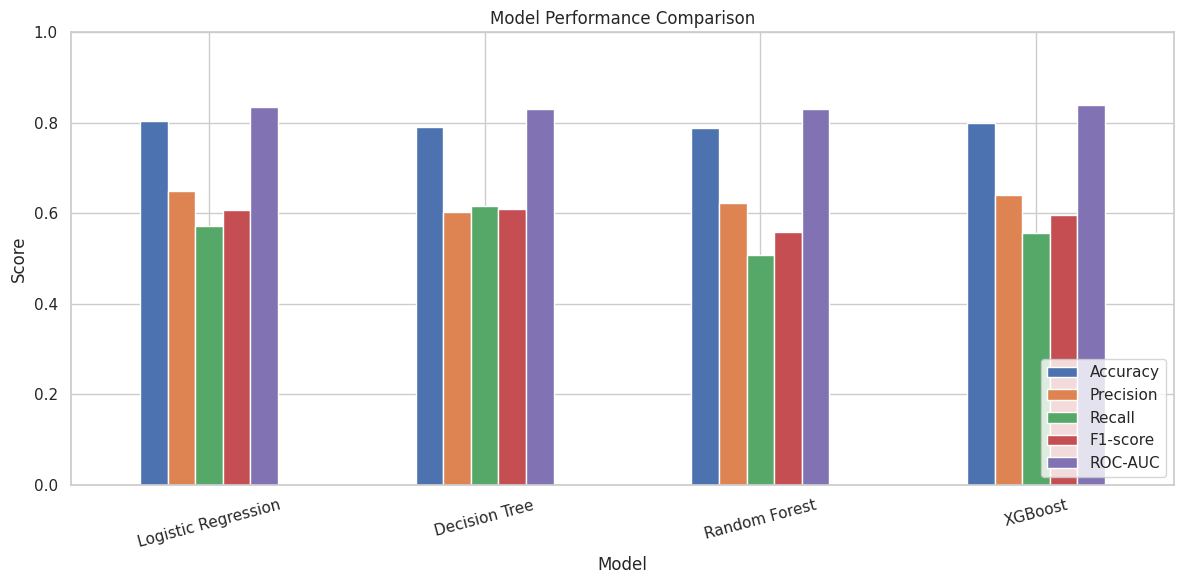

In [30]:
# 모델별 성능 비교 시각화
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC']

results_plot = results_df.set_index('Model')[metrics]

results_plot.plot(kind='bar', figsize=(12, 6))

plt.title('Model Performance Comparison')
plt.xlabel('Model')
plt.ylabel('Score')
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### 6.2 모델 성능 비교

네 가지 머신러닝 모델의 성능 평가 결과는 다음과 같다.

- **Logistic Regression**은 Accuracy(0.8038)와 Precision(0.6485)에서 가장 높은 성능을 보였다.
- **Decision Tree**는 Recall(0.6150)과 F1-score(0.6085)에서 가장 높은 성능을 보였다.
- **Random Forest**는 다른 모델에 비해 상대적으로 낮은 F1-score(0.5596)를 기록하였다.
- **XGBoost**는 ROC-AUC(0.8398)에서 가장 높은 성능을 보였다.

전체적으로 네 모델의 성능은 큰 차이를 보이지 않았으며, 평가 지표에 따라 우수한 모델이 다르게 나타났다.

특히 고객 이탈 예측에서는 실제 이탈 고객을 얼마나 잘 찾아내는지를 나타내는 Recall도 중요하다. 따라서 Accuracy만으로 모델의 성능을 판단하기보다는 여러 평가 지표를 종합적으로 고려해야 한다.

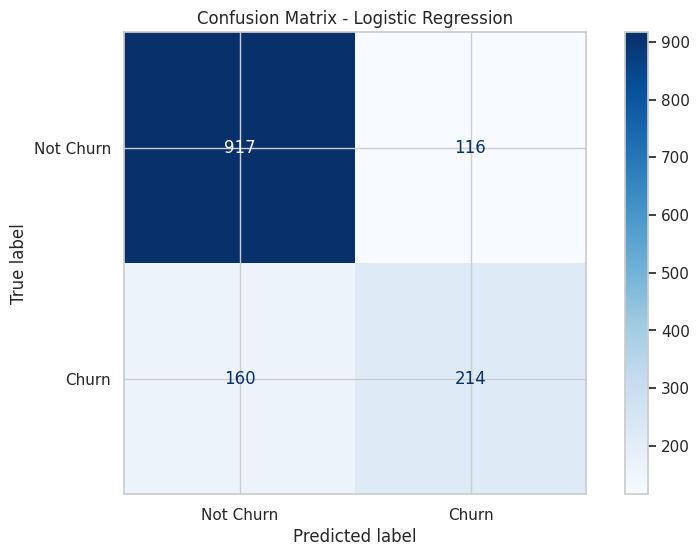

In [31]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Logistic Regression 모델의 혼동 행렬 생성
cm = confusion_matrix(y_test, lr_predictions, labels=['No', 'Yes'])

# 혼동 행렬 시각화
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Churn', 'Churn']
)

disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

### 6.3 혼동 행렬 분석

Logistic Regression 모델의 혼동 행렬을 분석한 결과는 다음과 같다.

- 실제로 서비스를 유지한 고객 중 917명을 올바르게 예측하였다.
- 실제로 이탈한 고객 중 214명을 올바르게 예측하였다.
- 서비스 유지 고객 116명을 이탈 고객으로 잘못 예측하였다.
- 실제 이탈 고객 160명을 유지 고객으로 잘못 예측하였다.

특히 실제 이탈 고객 중 160명을 예측하지 못했다는 점에서 개선의 여지가 있다. 고객 이탈을 사전에 방지하기 위해서는 실제 이탈 고객을 더 많이 찾아낼 수 있도록 Recall을 개선하는 것이 중요하다.

# 7. 주요 요인 분석 및 결론

## 7.1 주요 요인 분석

고객 이탈에 영향을 미치는 주요 요인을 파악하기 위해 Random Forest 모델의 Feature Importance를 분석한다.

Feature Importance는 각 변수가 모델의 예측에 얼마나 기여하는지를 나타내는 지표이다. 이를 통해 고객 이탈 예측에 중요한 변수를 확인하고자 한다.

In [32]:
# 전처리 후 생성된 특성 이름 가져오기
feature_names = preprocessor.get_feature_names_out()

# Random Forest 모델의 중요도 추출
importances = rf_model.feature_importances_

# 중요도 데이터프레임 생성
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

# 중요도가 높은 순서로 정렬
feature_importance_df = feature_importance_df.sort_values(
    by='Importance',
    ascending=False
)

# 상위 15개 특성 출력
display(feature_importance_df.head(15).round(4))

,Feature,Importance
42,num__tenure,0.1428
44,num__TotalCharges,0.1275
43,num__MonthlyCharges,0.0945
32,cat__Contract_Month-to-month,0.0769
14,cat__OnlineSecurity_No,0.0556
39,cat__PaymentMethod_Electronic check,0.0435
23,cat__TechSupport_No,0.0429
12,cat__InternetService_Fiber optic,0.0407
34,cat__Contract_Two year,0.0401
17,cat__OnlineBackup_No,0.0192


### 7.2 주요 요인 분석 결과

Random Forest 모델의 Feature Importance 분석 결과, 고객 이탈 예측에 중요한 상위 변수는 다음과 같다.

1. **tenure (0.1428)**: 고객이 서비스를 이용한 기간으로, 가장 높은 중요도를 기록하였다.
2. **TotalCharges (0.1275)**: 고객의 누적 요금으로, 이탈 예측에 중요한 변수로 나타났다.
3. **MonthlyCharges (0.0945)**: 고객의 월별 요금으로, 높은 중요도를 보였다.
4. **Contract_Month-to-month (0.0769)**: 월 단위 계약 여부로, 고객 이탈 예측에 중요한 계약 관련 변수이다.
5. **OnlineSecurity_No (0.0556)**: 온라인 보안 서비스를 이용하지 않는 여부로, 비교적 높은 중요도를 보였다.

분석 결과, 고객의 서비스 이용 기간과 요금 관련 변수, 계약 유형 및 부가 서비스 이용 여부가 고객 이탈 예측에 중요한 역할을 하는 것으로 나타났다.

이는 앞서 수행한 데이터 시각화 결과와도 일부 일치한다. 특히 월 단위 계약 고객의 이탈률이 높았다는 결과를 통해 계약 유형이 고객 이탈과 관련이 있음을 확인할 수 있다.

단, Feature Importance는 모델의 예측 기여도를 나타내며 변수 간 인과관계를 직접적으로 의미하지는 않는다.

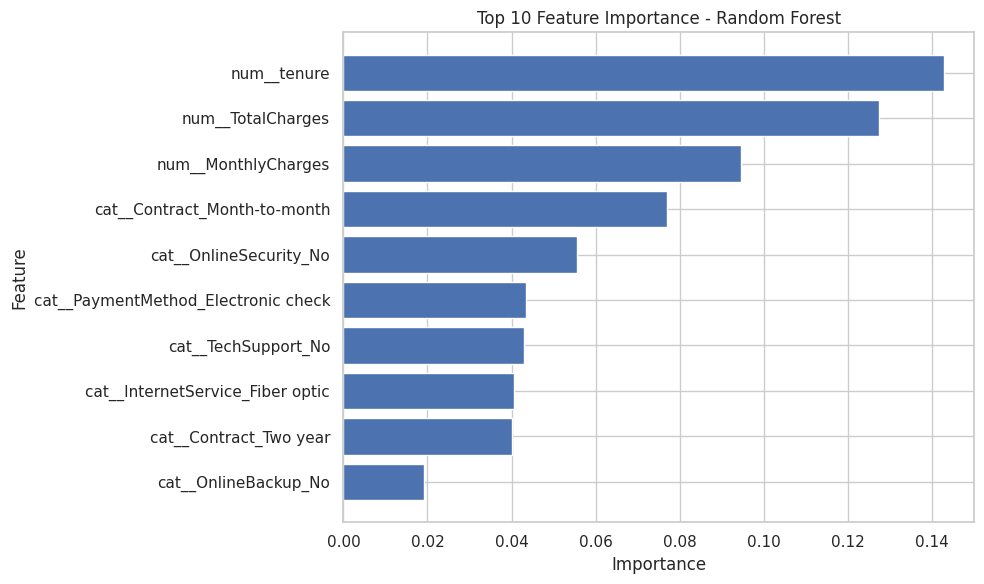

In [33]:
# 상위 10개 특성 선택
top_features = feature_importance_df.head(10).sort_values(
    by='Importance',
    ascending=True
)

# 특성 중요도 시각화
plt.figure(figsize=(10, 6))
plt.barh(top_features['Feature'], top_features['Importance'])

plt.title('Top 10 Feature Importance - Random Forest')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## 7.3 프로젝트 결론

본 프로젝트에서는 IBM Telco Customer Churn 데이터를 활용하여 통신 서비스 고객의 이탈 여부를 예측하고, 고객 이탈 예측에 중요한 요인을 분석하였다.

데이터 탐색 및 시각화 결과, 월 단위 계약 고객과 서비스 이용 기간이 짧은 고객의 이탈률이 상대적으로 높게 나타났다. 또한 전자 수표(Electronic check)를 결제 수단으로 사용하는 고객과 Fiber optic 서비스를 이용하는 고객에서도 비교적 높은 이탈률을 확인하였다.

네 가지 머신러닝 모델(Logistic Regression, Decision Tree, Random Forest, XGBoost)의 성능을 비교한 결과, 다음과 같은 특징을 확인하였다.

- Logistic Regression은 Accuracy 0.8038로 가장 높은 정확도를 기록하였다.
- Decision Tree는 Recall 0.6150과 F1-score 0.6085로 가장 높은 값을 기록하였다.
- XGBoost는 ROC-AUC 0.8398로 가장 높은 성능을 보였다.

Random Forest의 Feature Importance 분석에서는 tenure, TotalCharges, MonthlyCharges, Contract_Month-to-month 등이 고객 이탈 예측에 중요한 변수로 나타났다.

이를 통해 고객의 서비스 이용 기간, 요금 및 계약 유형이 고객 이탈 예측에 중요한 정보임을 확인하였다.

### 7.4 분석의 한계 및 향후 개선 방향

본 프로젝트는 제공된 데이터와 네 가지 머신러닝 모델을 기반으로 분석을 수행하였으므로 다음과 같은 한계가 있다.

- 사용한 데이터가 특정 통신 서비스 고객 데이터에 한정되어 있어 다른 기업이나 시장에 동일한 결과를 적용하기 어렵다.
- 모델의 예측 결과만으로 고객 이탈의 직접적인 원인을 확정할 수 없다.
- 실제 고객 이탈을 더 정확하게 예측하기 위해 추가적인 변수와 다양한 모델을 활용한 분석이 필요하다.

향후에는 모델의 하이퍼파라미터 최적화와 추가적인 특성 분석을 통해 예측 성능을 개선하고, 고객 이탈 가능성이 높은 고객을 대상으로 한 맞춤형 유지 전략을 연구할 수 있을 것이다.